# Link Prediction from Graph Similarity and Node Embeddings

**Author: Apostolos Stefanos Tzellas**

We reconstruct hidden similarity links in the **DBpedia similarities network**. The analysis compares a Jaccard threshold rule, a tuned Random Forest using three neighborhood measures, and Node2Vec embeddings combined through several symmetric edge operators.

The complete workflow includes graph preprocessing, disconnected-component preservation, top candidate links, threshold curves, feature correlations, model selection, held-out predictions, the score for nodes 1 and 47, Node2Vec training, all four edge-operator comparisons, and visual diagnostics. This is reconstruction of missing observed links, not a forecast of future interactions.

## Key findings

On the held-out DBpedia pairs, the neighborhood-feature Random Forest outperforms the tested Node2Vec classifiers in both average precision and default-threshold F1:

| Model | Precision | Recall | F1 | Average precision |
|---|---:|---:|---:|---:|
| Similarity RF — unweighted baseline | 1.000 | 0.439 | 0.610 | 0.606 |
| Similarity RF — balanced | 0.075 | 0.667 | 0.134 | 0.591 |
| Node2Vec — sum / average | 1.000 | 0.386 | 0.557 | 0.545 |
| Node2Vec — Hadamard | 1.000 | 0.351 | 0.519 | 0.488 |
| Node2Vec — L1 | 0.000 | 0.000 | 0.000 | 0.459 |
| Node2Vec — L2 | 0.000 | 0.000 | 0.000 | 0.460 |

The test split contains **57 hidden links**. The unweighted similarity model recovers **25** with **zero observed false alarms**; balancing recovers **38** but produces **472 false alarms**. Zero observed false alarms on this split does not guarantee perfect precision on new data.

Only **0.25%** of candidates are positive, so predicting no links already gives about **99.75% accuracy**. L1 and L2 illustrate why ranking quality and the decision threshold must be evaluated separately: their scores contain ranking information, but their default decisions recover no links.

These results describe one transductive edge-reconstruction split. The embedding models use shallow classifiers while the similarity models are tuned, so the comparison evaluates the stated pipelines rather than isolating representation quality.


## Setup and reproducibility

Run from top to bottom in Jupyter, VS Code, or Colab. Every analysis function is defined here; no other notebook or local Python package is required. The first cell installs the dependencies. Run installation in one notebook at a time if they share a Python environment; restart the kernel if packages were replaced.

Real datasets are downloaded from the sources listed below and cached in the system temporary directory. Their SHA-256 hashes identify the snapshots used. After a cache is cleared, the next run downloads them again. Download failures stop the affected analysis explicitly; a different graph is never substituted. Edges are unweighted and undirected unless a section explicitly states otherwise.

In [ ]:
%pip install -q "numpy>=1.26,<2" "scipy>=1.11,<2" "networkx>=3.2,<4" "pandas>=2,<3" "matplotlib>=3.7,<4" "scikit-learn>=1.3,<2" tqdm "node2vec==0.5.0" "gensim>=4.4,<5"

In [1]:
from pathlib import Path
import gzip
import hashlib
import io
import json
import math
import random
import tempfile
import time
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tqdm.auto import tqdm
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False})

SEED = 0

In [2]:
CACHE = Path(tempfile.gettempdir()) / "social-network-data"
CACHE.mkdir(parents=True, exist_ok=True)
SOURCES = {
    "download.tsv.dbpedia-similar.tar.bz2": "https://konect.cc/files/download.tsv.dbpedia-similar.tar.bz2"
}
SHA256 = {
    "download.tsv.dbpedia-similar.tar.bz2": "daa4b96e5aee669b2ab6809ff5b87252719ca6505bd8ea97bb2ed4ff28e785ad"
}

def fetch_data(name):
    """Download once, validate the snapshot, and reuse the cached data."""
    path = CACHE / name
    if path.exists() and hashlib.sha256(path.read_bytes()).hexdigest() == SHA256[name]:
        return path
    request = urllib.request.Request(SOURCES[name], headers={"User-Agent": "NetworkAnalysis/1.0"})
    try:
        with urllib.request.urlopen(request, timeout=120) as response:
            content = response.read()
    except Exception as error:
        raise RuntimeError(f"Cannot download {name} from {SOURCES[name]}. "
                           f"Check internet access and rerun this cell. Details: {error}") from error
    if hashlib.sha256(content).hexdigest() != SHA256[name]:
        raise ValueError(f"{name} differs from the documented dataset snapshot. "
                         "Inspect the source before changing its expected SHA-256.")
    # A unique temporary name also avoids conflicts between concurrently running notebooks.
    with tempfile.NamedTemporaryFile(dir=CACHE, delete=False) as temporary:
        temporary.write(content)
        temporary_path = Path(temporary.name)
    temporary_path.replace(path)
    return path


## Loading and validating the DBpedia graph

The [KONECT DBpedia similarities dataset](https://konect.cc/networks/dbpedia-similar/) contains Wikipedia/DBpedia concepts connected by a recorded similarity relationship. It is undirected. The published snapshot includes one self-loop; we preserve all nodes and remove self-loops before predicting links between distinct nodes.

The edge list is read directly from the compressed archive. We validate repeated edges using unordered endpoint pairs, so reversing an edge does not create a second relationship.

In [3]:
import tarfile
from itertools import combinations
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

with tarfile.open(fetch_data("download.tsv.dbpedia-similar.tar.bz2"), "r:bz2") as archive:
    member = next(member for member in archive.getmembers() if member.isfile() and Path(member.name).name == "out.dbpedia-similar")
    lines = archive.extractfile(member).read().decode("utf-8").splitlines()
raw_edges = []
for line in lines:
    if line.strip() and not line.lstrip().startswith(("%", "#")):
        columns = line.split()
        raw_edges.append(tuple(map(int, columns[:2])))
raw_keys = [tuple(sorted(edge)) for edge in raw_edges]
print(f"Raw edge rows: {len(raw_edges)}; duplicate undirected rows: {len(raw_keys)-len(set(raw_keys))}")
G = nx.Graph()
G.add_nodes_from(sorted({node for edge in raw_edges for node in edge}))
G.add_edges_from(sorted(set(raw_keys)))
loops = list(nx.selfloop_edges(G))
G.remove_edges_from(loops)
print(f"Removed {len(loops)} self-loop(s)")

def statistics(graph):
    return {"nodes": len(graph), "edges": graph.number_of_edges(),
            "mean_degree": 2*graph.number_of_edges()/len(graph),
            "components": nx.number_connected_components(graph)}

display(pd.DataFrame([statistics(G)], index=["Original DBpedia graph"]))

Raw edge rows: 565; duplicate undirected rows: 0
Removed 1 self-loop(s)


,nodes,edges,mean_degree,components
Original DBpedia graph,430,564,2.6233,95


## Hiding links while preserving every component

We build a spanning forest and hide **all edges outside that forest** to evaluate recovery of cycle-forming relationships. The remaining graph contains every original node and exactly the same connected components. These edges form a jointly removable set; they are not necessarily the set of all edges that could be removed individually.

Positive candidates are the hidden edges. Negative candidates are pairs absent from the original graph. Explicit node IDs and one canonical pair order keep labels, features, and predictions aligned throughout the analysis. The strong class imbalance is measured before interpreting accuracy.

Hidden positive links: 229
Original non-edges: 91,671
Positive prevalence: 0.2492%; no-link accuracy baseline: 99.7508%


,nodes,edges,mean_degree,components
original,430.0,564.0,2.6233,95.0
observed,430.0,335.0,1.5581,95.0


,pair,link
0,"(1, 6)",0
1,"(1, 7)",0
2,"(1, 8)",0
3,"(1, 9)",0
4,"(1, 10)",0
5,"(1, 11)",0
6,"(1, 12)",0
7,"(1, 13)",0


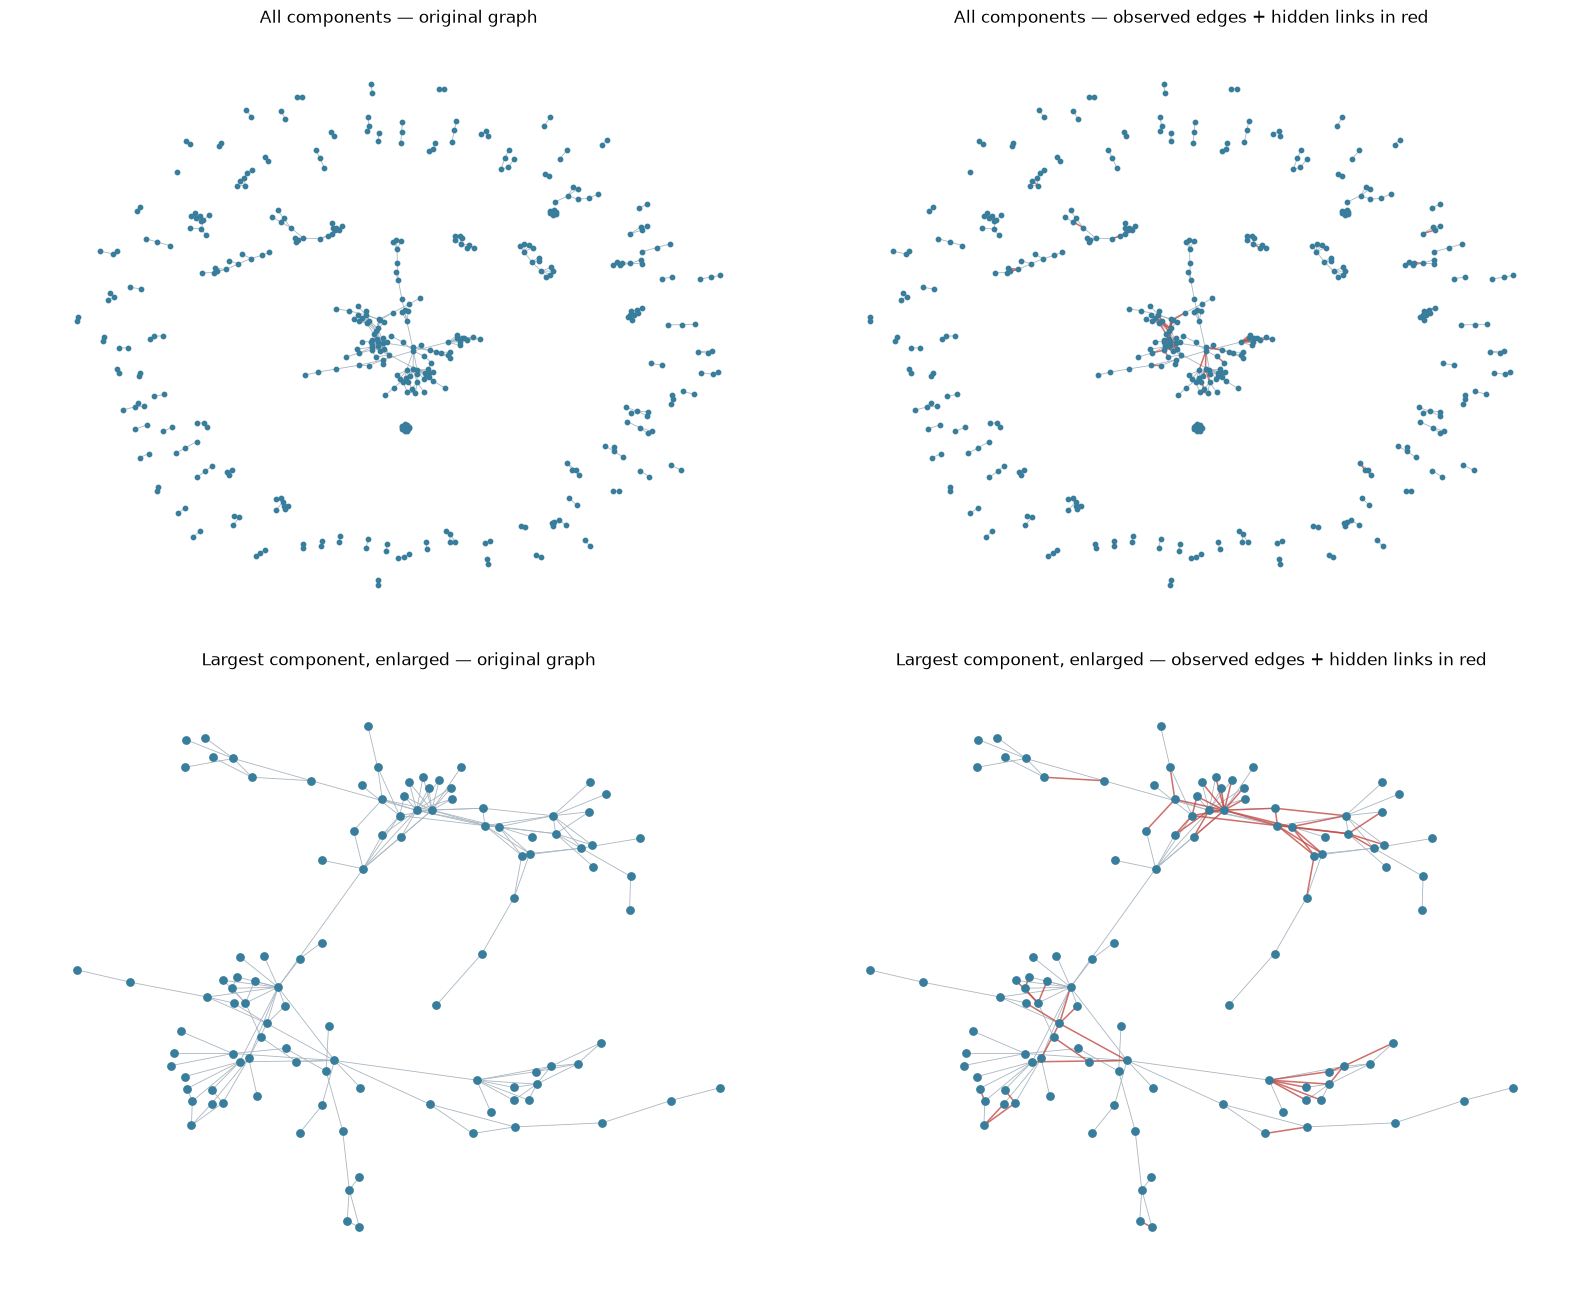

In [4]:
forest = nx.minimum_spanning_tree(G, weight=None)
forest_keys = {tuple(sorted(edge)) for edge in forest.edges()}
hidden_edges = [edge for edge in sorted(tuple(sorted(edge)) for edge in G.edges()) if edge not in forest_keys]
negative_pairs = [pair for pair in combinations(sorted(G), 2) if not G.has_edge(*pair)]
G_reduced = G.copy()
G_reduced.remove_edges_from(hidden_edges)
assert set(G_reduced) == set(G)
assert {frozenset(c) for c in nx.connected_components(G_reduced)} == {frozenset(c) for c in nx.connected_components(G)}
assert all(not G_reduced.has_edge(*edge) for edge in hidden_edges)
pairs = negative_pairs + hidden_edges
y = np.array([0]*len(negative_pairs)+[1]*len(hidden_edges), dtype=int)
assert len(set(pairs)) == len(pairs)
candidates = pd.DataFrame({"pair": pairs, "link": y})
display(pd.DataFrame({"original": statistics(G), "observed": statistics(G_reduced)}).T)
print(f"Hidden positive links: {len(hidden_edges):,}")
print(f"Original non-edges: {len(negative_pairs):,}")
print(f"Positive prevalence: {y.mean():.4%}; no-link accuracy baseline: {1-y.mean():.4%}")
display(candidates.head(8))
position = nx.spring_layout(G, seed=SEED, weight=None)
largest_nodes = max(nx.connected_components(G), key=len)
zoom_graph = G.subgraph(largest_nodes)
zoom_position = nx.spring_layout(zoom_graph, k=.3, iterations=100, seed=SEED, weight=None)
zoom_hidden = [edge for edge in hidden_edges if edge[0] in largest_nodes and edge[1] in largest_nodes]
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for row, (nodes, layout, removed, label) in enumerate([
    (set(G), position, hidden_edges, "All components"),
    (largest_nodes, zoom_position, zoom_hidden, "Largest component, enlarged")]):
    for column, observed in enumerate([False, True]):
        ax = axes[row, column]
        graph = (G_reduced if observed else G).subgraph(nodes)
        nx.draw_networkx_nodes(graph, layout, ax=ax, node_size=10 if row==0 else 28, node_color="#387e9c")
        nx.draw_networkx_edges(graph, layout, ax=ax, edge_color="#a9b6c0", width=.6)
        if observed:
            nx.draw_networkx_edges(G.subgraph(nodes), layout, edgelist=removed,
                ax=ax, edge_color="#c24b46", width=1.1, alpha=.8)
        ax.set_title(label+(" — observed edges + hidden links in red" if observed else " — original graph"))
        ax.set_axis_off()
plt.tight_layout()
plt.show()


### What edge hiding changes

Keeping only a spanning forest removes every cycle. Component membership is preserved, but local neighborhoods and random-walk contexts become much sparser. Consequently this is a demanding and structurally biased reconstruction task: bridge edges are always protected, while cycle edges become positives. Neither performance on arbitrary removed edges nor performance on future links follows directly from this setup.

Most candidate pairs are negatives, and many connect different components. Those pairs can be easy to reject; high aggregate accuracy can therefore conceal failure to recover hidden links.

## Jaccard similarity: ranked pairs and threshold behavior

Jaccard is the intersection of two neighbor sets divided by their union. A value of one means identical nonempty neighbor sets. In a forest, different leaves attached to the same center can therefore receive one even if they are not connected. The eight highest-ranked candidates below illustrate the strongest neighborhood matches, including tied scores.

We compare thresholds of 0.10, 0.15, 0.25, 0.50, and 1.00. Precision is reported as zero when a rule predicts no positive links. This full-candidate diagnostic describes the rule; it is not used to choose a threshold from the held-out classifier test set.

Pairs tied at Jaccard=1: 318


,pair,Jaccard,link
425,"(2, 4)",1.0,0
9150,"(23, 25)",1.0,0
9152,"(23, 27)",1.0,0
9156,"(23, 31)",1.0,0
9158,"(23, 33)",1.0,0
9159,"(23, 34)",1.0,0
9160,"(23, 35)",1.0,0
9960,"(25, 27)",1.0,0


,precision,recall,accuracy
threshold,,,
0.10,0.2912,0.7948,0.9947
0.15,0.3210,0.7948,0.9953
0.25,0.3397,0.7773,0.9957
0.50,0.3827,0.7336,0.9964
1.00,0.4591,0.6376,0.9972


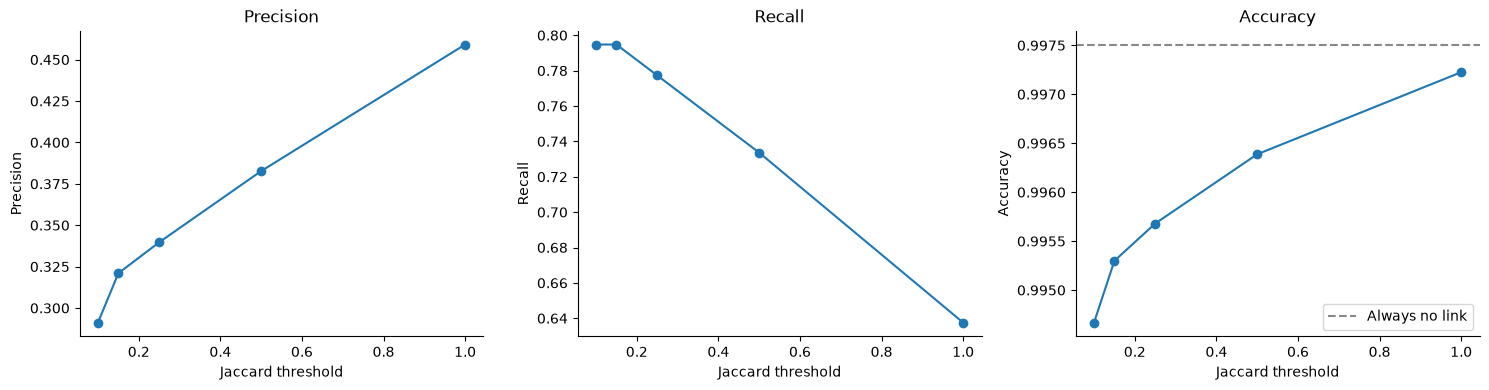

In [5]:
def similarity_features(graph, ordered_pairs):
    return np.column_stack([[score for _, _, score in function(graph, ordered_pairs)]
        for function in [nx.jaccard_coefficient, nx.preferential_attachment, nx.resource_allocation_index]])

X_similarity = similarity_features(G_reduced, pairs)
feature_names = ["Jaccard", "Preferential attachment", "Resource allocation"]
feature_table = candidates.copy()
feature_table[feature_names] = X_similarity
jaccard = X_similarity[:, 0]
ranking = np.argsort(-jaccard, kind="stable")
display(feature_table.iloc[ranking[:8]][["pair", "Jaccard", "link"]])
print(f"Pairs tied at Jaccard=1: {np.count_nonzero(np.isclose(jaccard, 1)):,}")
threshold_rows = []
for threshold in [.10, .15, .25, .50, 1.0]:
    prediction = (jaccard >= threshold).astype(int)
    threshold_rows.append({"threshold": threshold,
        "precision": precision_score(y, prediction, zero_division=0),
        "recall": recall_score(y, prediction, zero_division=0),
        "accuracy": accuracy_score(y, prediction)})
threshold_results = pd.DataFrame(threshold_rows).set_index("threshold")
display(threshold_results)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["precision", "recall", "accuracy"]):
    ax.plot(threshold_results.index, threshold_results[metric], marker="o")
    ax.set(xlabel="Jaccard threshold", ylabel=metric.capitalize(), title=metric.capitalize())
axes[2].axhline(1-y.mean(), color="#888888", linestyle="--", label="Always no link")
axes[2].legend()
plt.tight_layout()
plt.show()

### Interpreting the threshold curves

A stricter threshold usually reduces the number of proposed links, raising precision at the expense of recall, although neither trend is guaranteed to be monotonic on every dataset. The actual table establishes what happens here. Accuracy must be compared with the no-link baseline: rejecting the many negatives can dominate that metric.

The top eight are only one arbitrary ordering within tied scores; they are not necessarily uniquely best candidates. A strong Jaccard score measures neighborhood similarity, not a calibrated probability of an edge.

## Combining neighborhood measures

Preferential attachment is the product of endpoint degrees. Resource allocation sums the reciprocal degree of each common neighbor, discounting highly connected intermediaries. All three feature columns are computed on the **observed graph** for the **same ordered pair list**.

Pearson correlation measures linear dependence between feature values. Spearman correlation compares ranks and is useful when degree products are skewed. Correlation is descriptive: it neither measures predictive usefulness against the target nor proves that one feature is redundant.

,pair,link,Jaccard,Preferential attachment,Resource allocation
0,"(1, 6)",0,0.1667,12.0,0.5
1,"(1, 7)",0,0.0000,4.0,0.0
2,"(1, 8)",0,0.0000,12.0,0.0
3,"(1, 9)",0,0.0000,12.0,0.0
4,"(1, 10)",0,0.0000,8.0,0.0
5,"(1, 11)",0,0.0000,12.0,0.0
6,"(1, 12)",0,0.0000,8.0,0.0
7,"(1, 13)",0,0.0000,4.0,0.0
8,"(1, 14)",0,0.0000,8.0,0.0
9,"(1, 15)",0,0.0000,20.0,0.0


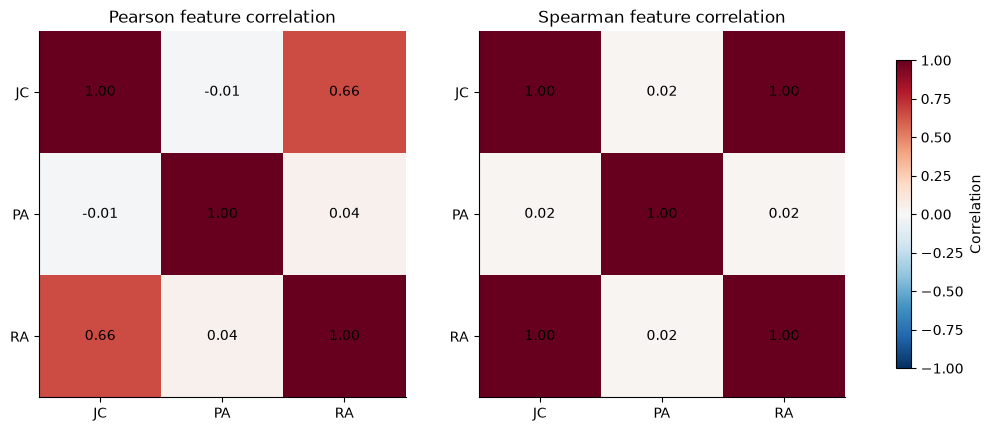

In [6]:
display(feature_table.head(10))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    correlation = feature_table[feature_names].corr(method=method)
    image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(3), ["JC", "PA", "RA"])
    ax.set_yticks(range(3), ["JC", "PA", "RA"])
    ax.set_title(method.capitalize()+" feature correlation")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{correlation.iloc[i,j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=axes, shrink=.8, label="Correlation")
plt.show()

## Random Forest: tuning and held-out predictions

We use a stratified 75/25 split with seed zero. The search covers 10, 50, or 100 trees and maximum depth 5, 10, or 15. Five stratified training folds select an **unweighted Random Forest baseline by accuracy**. We also fit a clearly separate balanced variant selected by **average precision**, which assesses ranking under imbalance. The test pairs never influence either search. This comparison measures the effect of changing the imbalance treatment and tuning objective.

Trees do not require feature scaling, so no scaler is fit. We report accuracy alongside precision, recall, F1, average precision, ROC-AUC, and the majority baseline. Average precision should be compared with positive prevalence. ROC-AUC can look favorable even when precision is poor on this sparse task.

In [7]:
train_indices, test_indices = train_test_split(np.arange(len(y)), test_size=.25, stratify=y, random_state=SEED)
y_train, y_test = y[train_indices], y[test_indices]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(RandomForestClassifier(random_state=SEED, class_weight="balanced", n_jobs=1),
    param_grid={"n_estimators": [10, 50, 100], "max_depth": [5, 10, 15]},
    scoring="average_precision", cv=cv, n_jobs=1, refit=True)
with threadpool_limits(limits=2):
    search.fit(X_similarity[train_indices], y_train)
similarity_model = search.best_estimator_
# Fit an unweighted, accuracy-selected comparison model.
baseline_search = GridSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=1),
    param_grid={"n_estimators": [10, 50, 100], "max_depth": [5, 10, 15]},
    scoring="accuracy", cv=cv, n_jobs=1, refit=True)
with threadpool_limits(limits=2):
    baseline_search.fit(X_similarity[train_indices], y_train)
baseline_model = baseline_search.best_estimator_
print("Unweighted RF baseline parameters:", baseline_search.best_params_)
print("Best training-CV parameters:", search.best_params_)
print(f"Mean training-CV average precision: {search.best_score_:.4f}")
display(pd.DataFrame(search.cv_results_)[["param_n_estimators", "param_max_depth", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score"))

def evaluate_model(model, features):
    scores = model.predict_proba(features[test_indices])[:, list(model.classes_).index(1)]
    predicted = model.predict(features[test_indices])
    return {"accuracy": accuracy_score(y_test, predicted),
            "precision": precision_score(y_test, predicted, zero_division=0),
            "recall": recall_score(y_test, predicted, zero_division=0),
            "F1": f1_score(y_test, predicted, zero_division=0),
            "average_precision": average_precision_score(y_test, scores),
            "ROC_AUC": roc_auc_score(y_test, scores),
            "no_link_accuracy": 1-y_test.mean(), "prevalence": y_test.mean()}, scores, predicted

metrics, model_scores, model_predictions = {}, {}, {}
metrics["Similarity RF baseline"], model_scores["Similarity RF baseline"], model_predictions["Similarity RF baseline"] = evaluate_model(baseline_model, X_similarity)
metrics["Similarity RF balanced"], model_scores["Similarity RF balanced"], model_predictions["Similarity RF balanced"] = evaluate_model(similarity_model, X_similarity)
display(pd.DataFrame(metrics).T)
first_predictions = candidates.iloc[test_indices[:8]].copy()
first_predictions["predicted_link"] = model_predictions["Similarity RF baseline"][:8]
first_predictions["link_score"] = model_scores["Similarity RF baseline"][:8]
display(first_predictions)
query = (1, 47)
if set(query).issubset(G_reduced):
    query_features = similarity_features(G_reduced, [query])
    query_score = baseline_model.predict_proba(query_features)[0, list(baseline_model.classes_).index(1)]
    matching = [i for i, pair in enumerate(pairs) if pair == query]
    split = "training pair" if matching and matching[0] in set(train_indices) else "held-out pair" if matching else "already observed edge"
    print(f"Nodes {query}: model link score={query_score:.6f}; status={split}")
    print("This Random Forest score is not a calibrated probability of a future relationship.")
else:
    print("The requested query nodes are absent from this dataset snapshot.")

Unweighted RF baseline parameters: {'max_depth': 5, 'n_estimators': 10}
Best training-CV parameters: {'max_depth': 10, 'n_estimators': 100}
Mean training-CV average precision: 0.6982
Nodes (1, 47): model link score=0.120306; status=training pair
This Random Forest score is not a calibrated probability of a future relationship.


,param_n_estimators,param_max_depth,mean_test_score,std_test_score,rank_test_score
5,100,10,0.6982,0.1143,1
2,100,5,0.6980,0.1239,2
4,50,10,0.6972,0.1155,3
1,50,5,0.6956,0.1246,4
7,50,15,0.6956,0.1114,5
8,100,15,0.6950,0.1122,6
3,10,10,0.6833,0.1239,7
0,10,5,0.6809,0.1223,8
6,10,15,0.6772,0.1235,9


,accuracy,precision,recall,F1,average_precision,ROC_AUC,no_link_accuracy,prevalence
Similarity RF baseline,0.9986,1.0000,0.4386,0.6098,0.6059,0.9269,0.9975,0.0025
Similarity RF balanced,0.9786,0.0745,0.6667,0.1340,0.5914,0.8986,0.9975,0.0025


,pair,link,predicted_link,link_score
91781,"(333, 336)",1,1,1.0000
11842,"(29, 313)",0,0,0.0007
8661,"(21, 350)",0,0,0.0002
88328,"(348, 349)",0,0,0.0006
2506,"(6, 396)",0,0,0.0006
49403,"(138, 324)",0,0,0.0002
23962,"(61, 154)",0,0,0.0006
389,"(1, 395)",0,0,0.0008


## Node2Vec embeddings and edge operators

Node2Vec learns a 128-dimensional vector per node from ten random walks of length 80, with context window ten. Return and exploration parameters are both one, making these walks unbiased. Embeddings are trained on the reduced graph only, never on hidden edges. 

We use one worker, fixed seeds, and a stable hashing function for repeatability. The embedding baseline combines endpoint vectors by addition and uses a depth-two Random Forest. Average, Hadamard, absolute difference (L1), and squared difference (L2) are then compared with the same depth-two classifier and **exactly the same held-out pairs**.

In [8]:
from node2vec import Node2Vec

def stable_hash(value):
    return int.from_bytes(hashlib.blake2b(str(value).encode(), digest_size=8).digest(), "little")

walker = Node2Vec(G_reduced, p=1, q=1, dimensions=128, num_walks=10, walk_length=80,
                  workers=1, seed=SEED, weight_key="unused_weight", quiet=True)
embedding_model = walker.fit(window=10, min_count=1, epochs=5, seed=SEED, workers=1, hashfxn=stable_hash)
left_vectors = np.array([embedding_model.wv[str(u)] for u, v in pairs])
right_vectors = np.array([embedding_model.wv[str(v)] for u, v in pairs])
operators = {
    "Sum": lambda left, right: left+right,
    "Average": lambda left, right: (left+right)/2,
    "Hadamard": lambda left, right: left*right,
    "L1": lambda left, right: np.abs(left-right),
    "L2": lambda left, right: (left-right)**2,
}
for operator, combine in tqdm(operators.items(), desc="Embedding operators"):
    features = combine(left_vectors, right_vectors)
    classifier = RandomForestClassifier(n_estimators=100, max_depth=2, random_state=SEED, n_jobs=1)
    classifier.fit(features[train_indices], y_train)
    name = "Node2Vec "+operator
    metrics[name], model_scores[name], model_predictions[name] = evaluate_model(classifier, features)
display(pd.DataFrame(metrics).T)

Embedding operators: 100%|##########| 5/5 [00:55<00:00, 11.14s/it]


,accuracy,precision,recall,F1,average_precision,ROC_AUC,no_link_accuracy,prevalence
Similarity RF baseline,0.9986,1.0000,0.4386,0.6098,0.6059,0.9269,0.9975,0.0025
Similarity RF balanced,0.9786,0.0745,0.6667,0.1340,0.5914,0.8986,0.9975,0.0025
Node2Vec Sum,0.9985,1.0000,0.3860,0.5570,0.5455,0.9102,0.9975,0.0025
Node2Vec Average,0.9985,1.0000,0.3860,0.5570,0.5455,0.9102,0.9975,0.0025
Node2Vec Hadamard,0.9984,1.0000,0.3509,0.5195,0.4876,0.8843,0.9975,0.0025
Node2Vec L1,0.9975,0.0000,0.0000,0.0000,0.4593,0.9048,0.9975,0.0025
Node2Vec L2,0.9975,0.0000,0.0000,0.0000,0.4602,0.9208,0.9975,0.0025


### What the operator comparison tests

The operators encode different notions of pair similarity. Hadamard keeps dimension-wise agreement, while L1 and L2 emphasize distances. Sum and average differ only by a constant factor, so a tree model should produce equivalent decisions apart from numerical edge cases; matching results for those two operators are expected.

The embedding classifiers use a depth-two, unweighted Random Forest. They are not tuned like the similarity model, so differences reflect both representation and classifier capacity. If they predict no positive links, high accuracy does not validate the representation. Sparse disconnected walks, few positives, and shallow trees can all limit recovery. The precision–recall curves and confusion matrices separate useful rankings from successful recovery at the default threshold.

## Visual diagnostics: ranking quality and actual link recovery

Precision–recall curves compare models over decision thresholds using the held-out pairs. The dashed prevalence line is the uninformative ranking reference. Average precision summarizes the curve. The confusion matrices show the exact counts of recovered links, false alarms, missed links, and correctly rejected non-links at each model's default decision rule.

These diagnostics are reported after model selection; they are not used to tune on the test set.

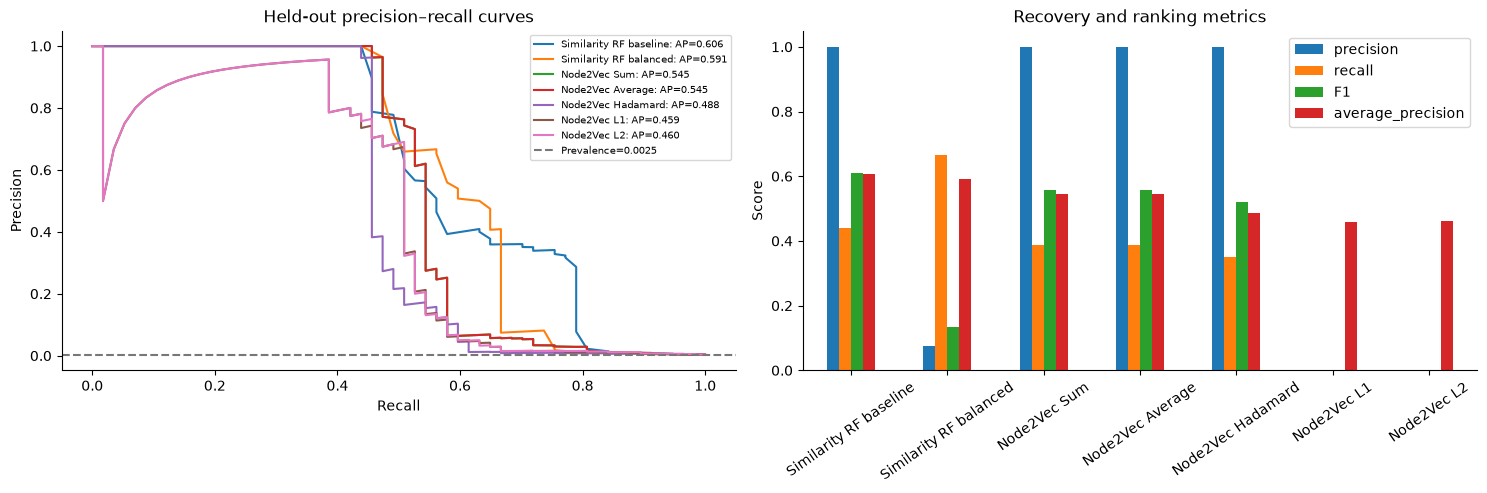

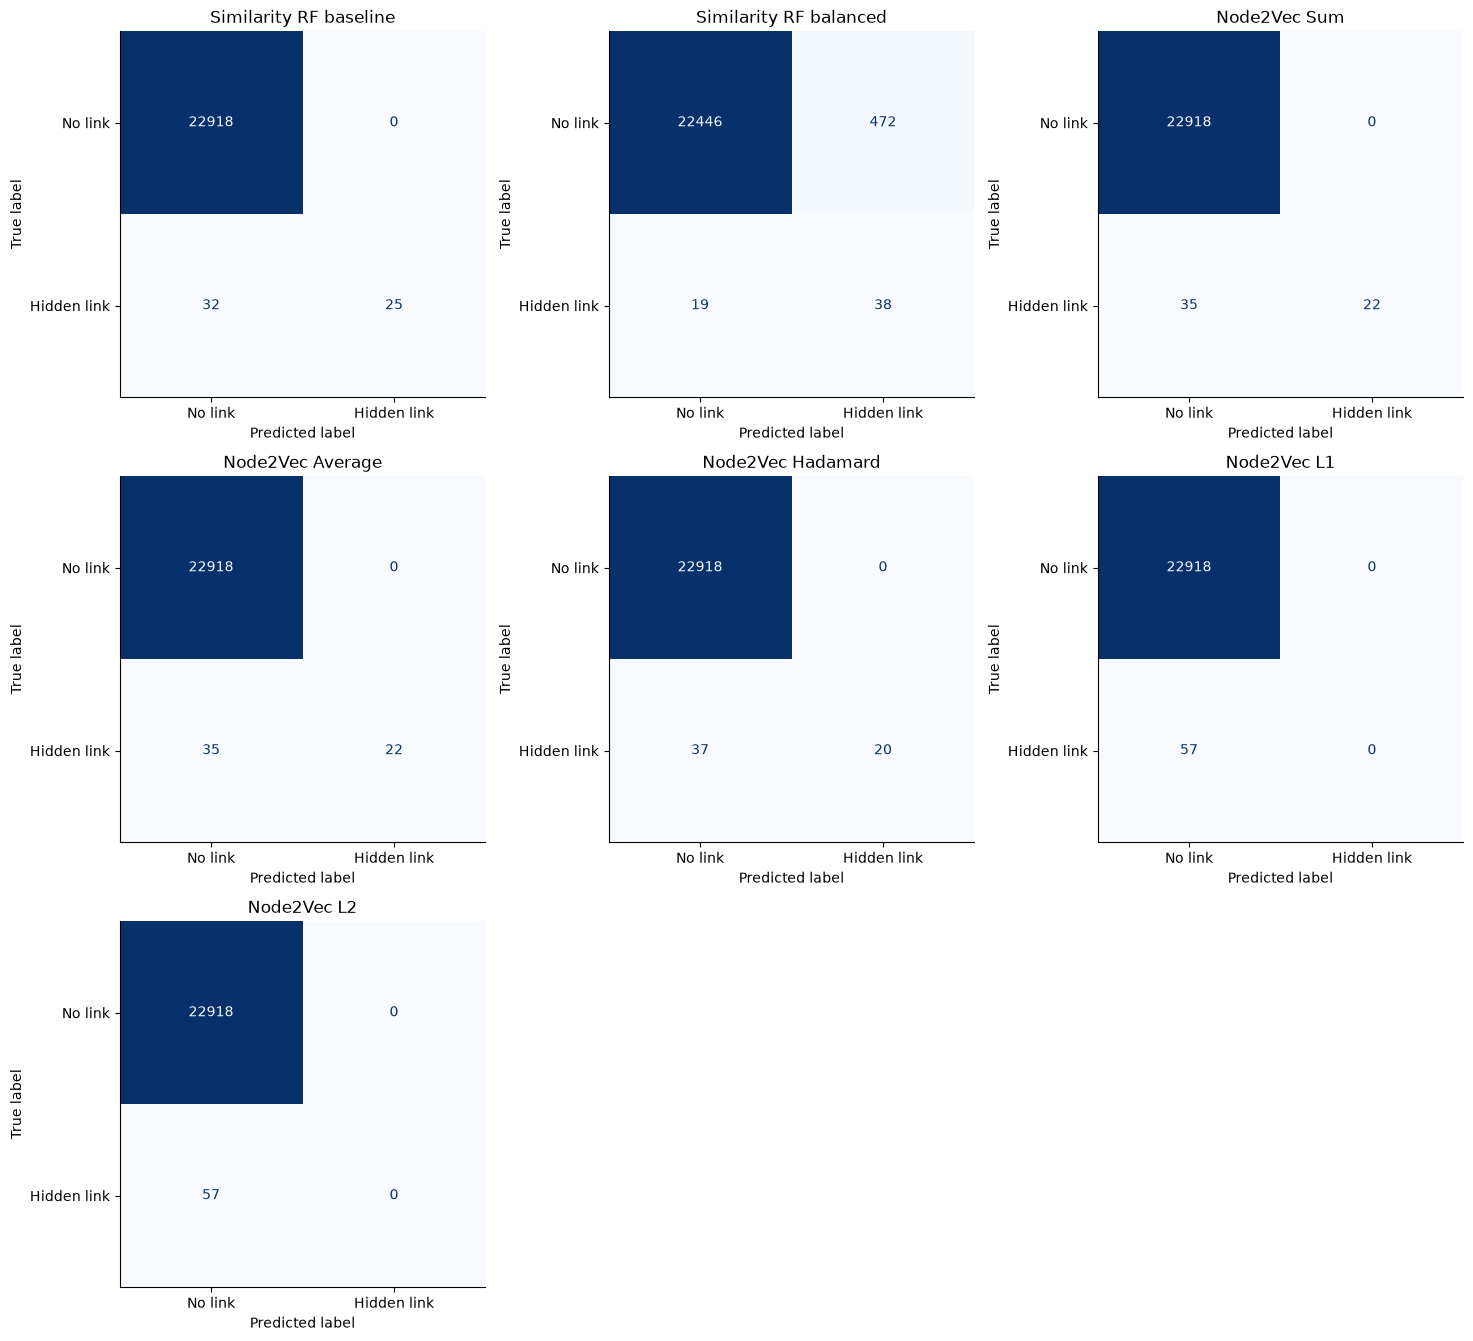

The balanced similarity model recovers **38** hidden links, misses **19**, and raises **472** false alarms. Its precision is **0.075**, recall **0.667**, and average precision **0.591**, against prevalence **0.0025**. These counts show what the accuracy figure alone hides.

**Ranking and decisions answer different questions.** The highest held-out average precision is **0.606** from **Similarity RF baseline**. The highest default-threshold F1 is **0.610** from **Similarity RF baseline**. Models recovering no hidden links at their default threshold: **Node2Vec L1, Node2Vec L2**. A model can rank useful candidates above others while its decision threshold still produces no positive predictions.

The **unweighted RF baseline** recovers **25 of 57** test links with **0** false alarms. The balanced variant recovers **38** but produces **472** false alarms. Balancing is therefore a trade-off to evaluate, not an automatic improvement. A precision of one on this finite split means no false alarms were observed here; it does not guarantee perfect precision on new data.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, scores in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(recall, precision, label=f"{name}: AP={metrics[name]['average_precision']:.3f}")
axes[0].axhline(y_test.mean(), color="#777777", linestyle="--", label=f"Prevalence={y_test.mean():.4f}")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Held-out precision–recall curves")
axes[0].legend(fontsize=7)
metric_table = pd.DataFrame(metrics).T
metric_table[["precision", "recall", "F1", "average_precision"]].plot.bar(ax=axes[1], rot=35)
axes[1].set(title="Recovery and ranking metrics", ylabel="Score")
plt.tight_layout()
plt.show()
rows = math.ceil(len(model_predictions)/3)
fig, axes = plt.subplots(rows, 3, figsize=(15, 4.5*rows))
for ax, (name, prediction) in zip(axes.flat, model_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, prediction, labels=[0, 1],
        display_labels=["No link", "Hidden link"], ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(name)
for ax in list(axes.flat)[len(model_predictions):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()
name = "Similarity RF balanced"
tn, fp, fn, tp = confusion_matrix(y_test, model_predictions[name], labels=[0, 1]).ravel()
display(Markdown(f"The balanced similarity model recovers **{tp}** hidden links, misses **{fn}**, and raises **{fp}** false alarms. "
    f"Its precision is **{metrics[name]['precision']:.3f}**, recall **{metrics[name]['recall']:.3f}**, "
    f"and average precision **{metrics[name]['average_precision']:.3f}**, against prevalence **{y_test.mean():.4f}**. "
    "These counts show what the accuracy figure alone hides."))
best_ranking = metric_table.average_precision.idxmax()
best_f1 = metric_table.F1.idxmax()
zero_recovery = metric_table.index[metric_table.recall.eq(0)].tolist()
display(Markdown(f"**Ranking and decisions answer different questions.** The highest held-out average precision is "
    f"**{metric_table.loc[best_ranking, 'average_precision']:.3f}** from **{best_ranking}**. "
    f"The highest default-threshold F1 is **{metric_table.loc[best_f1, 'F1']:.3f}** from **{best_f1}**. "
    f"Models recovering no hidden links at their default threshold: **{', '.join(zero_recovery) or 'none'}**. "
    "A model can rank useful candidates above others while its decision threshold still produces no positive predictions."))

baseline_tn, baseline_fp, baseline_fn, baseline_tp = confusion_matrix(
    y_test, model_predictions["Similarity RF baseline"], labels=[0, 1]).ravel()
display(Markdown(f"The **unweighted RF baseline** recovers **{baseline_tp} of {int(y_test.sum())}** test links "
    f"with **{baseline_fp}** false alarms. The balanced variant recovers **{tp}** but produces **{fp}** false alarms. "
    "Balancing is therefore a trade-off to evaluate, not an automatic improvement. "
    "A precision of one on this finite split means no false alarms were observed here; it does not guarantee perfect precision on new data."))


## Conclusions and limits

This workflow separates a neighborhood rule, a learned combination of neighborhood measures, and embeddings learned from graph walks. Explicit pair alignment and a shared split make the comparisons interpretable. Training-only cross-validation avoids selecting Random Forest parameters on the held-out pairs, and the visual diagnostics expose whether each method actually finds links.

The experiment remains **transductive**: training and test pairs share nodes and the observed graph. All non-edges are treated as negatives, including many cross-component pairs, and the hidden positives are specifically the non-forest edges. Those choices shape the difficulty and limit generalization. Random Forest scores are not calibrated probabilities; repeated split and edge-hiding experiments would be required to assess stability. Enumerating all pairs and storing 128-dimensional vectors for them has quadratic memory cost and is suitable for this 430-node network, not arbitrary large graphs.

**Sources:** [KONECT DBpedia similarities](https://konect.cc/networks/dbpedia-similar/), Jérôme Kunegis, *KONECT: The Koblenz Network Collection*, 2013; Auer et al., *DBpedia: A Nucleus for a Web of Open Data*, 2007; Grover and Leskovec, [*node2vec: Scalable Feature Learning for Networks*](https://cs.stanford.edu/~jure/pubs/node2vec-kdd16.pdf), 2016.